# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from pathlib import Path

# Works when Jupyter is started from week03/ or the repository root.
possible_paths = [Path('../data/co2_emissions.csv'), Path('data/co2_emissions.csv')]
csv_path = next((p for p in possible_paths if p.is_file()), None)
if csv_path is None:
    raise FileNotFoundError('Place co2_emissions.csv in the repository data/ folder.')

df = pd.read_csv(csv_path)
df = df.sort_values(['Country', 'Year']).reset_index(drop=True)
assert {'Country', 'Region', 'Year', 'CO2_Mt', 'CO2_per_capita'} <= set(df.columns)
assert not df[['Country', 'Region', 'Year', 'CO2_Mt', 'CO2_per_capita']].isna().any().any()
assert not df.duplicated(['Country', 'Year']).any()
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}–{df['Year'].max()}")
display(df.head())


Loaded: 345 rows | Countries: 15 | Years: 2000–2022


DataFrame preview: columns Country, Region, Year, CO2_Mt, CO2_per_capita; 345 observations.

In [2]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: ['United States' 'China' 'India' 'Germany' 'United Kingdom' 'France'
 'Brazil' 'Japan' 'Canada' 'Australia' 'South Korea' 'Russia'
 'South Africa' 'Mexico' 'Indonesia']

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


## Task 1 - A line chart showing CO2 per Capita for all countries in the dataset

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country/countries **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country/countries and its story

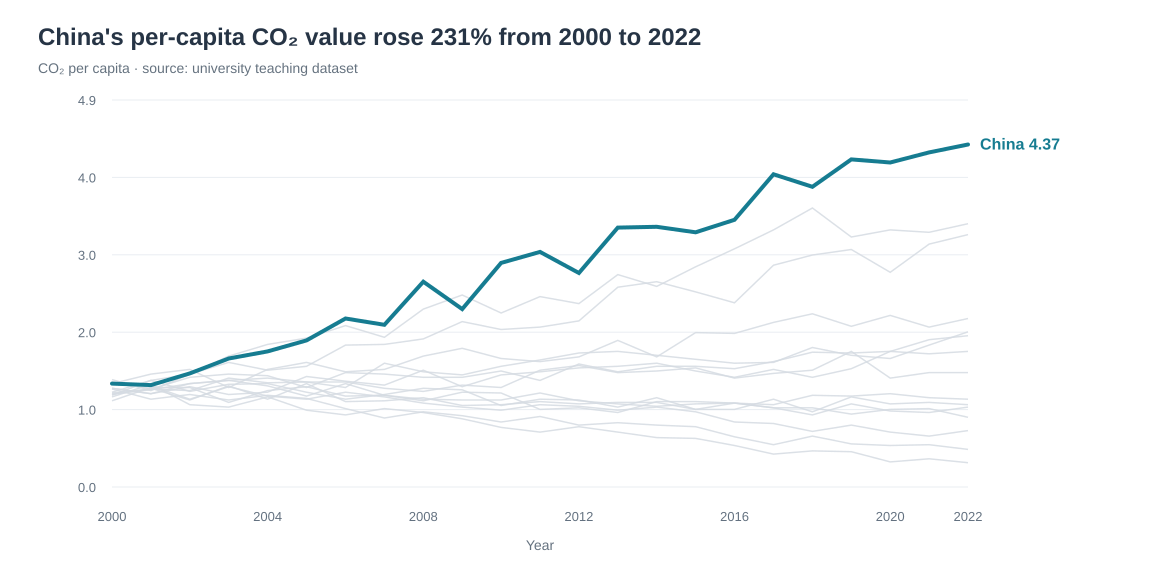

China: 1.32 (2000) → 4.37 (2022), +231.1% in the supplied data.


In [3]:
# Task 1: All countries for context; only China is highlighted.
highlight = 'China'
first_year, last_year = df['Year'].min(), df['Year'].max()
china = df[df['Country'] == highlight].sort_values('Year')
start = china.loc[china['Year'] == first_year, 'CO2_per_capita'].iloc[0]
end = china.loc[china['Year'] == last_year, 'CO2_per_capita'].iloc[0]
change_pct = (end / start - 1) * 100
fig1 = go.Figure()

# Thin grey lines for all 14 non-highlighted countries.
for country, country_data in df[df['Country'] != highlight].groupby('Country'):
    fig1.add_trace(go.Scatter(
        x=country_data['Year'], y=country_data['CO2_per_capita'],
        mode='lines', name=country, line=dict(color='#EEEEEE', width=1.5),
        hovertemplate=f'{country}<br>Year: %{{x}}<br>CO₂ per capita: %{{y:.2f}}<extra></extra>',
        showlegend=False
    ))

# Draw the coloured highlight last for visibility.
fig1.add_trace(go.Scatter(
    x=china['Year'], y=china['CO2_per_capita'],
    mode='lines', name=highlight, line=dict(color='#167C91', width=3.5),
    hovertemplate='China<br>Year: %{x}<br>CO₂ per capita: %{y:.2f}<extra></extra>',
    showlegend=False
))
fig1.add_annotation(
    x=last_year, y=end, text=f'<b>{highlight}</b>  {end:.2f}',
    showarrow=False, xanchor='left', xshift=10,
    font=dict(color='#167C91', size=13)
)
fig1.update_layout(
    title=dict(text=f"China's per-capita CO₂ value rose {change_pct:.0f}% from {first_year} to {last_year}", x=0.02),
    xaxis=dict(title=None, range=[first_year, last_year + 4], dtick=4,
               showgrid=False, showline=False, zeroline=False),
    yaxis=dict(title='CO₂ per capita (course dataset values)', rangemode='tozero',
               showgrid=True, gridcolor='#F3F3F3', zeroline=False, showline=False),
    template='plotly_white', height=460,
    margin=dict(l=88, r=125, t=88, b=50),
    font=dict(family='Arial', size=12, color='#283445'),
    paper_bgcolor='white', plot_bgcolor='white', showlegend=False
)
assert len(fig1.data) == df['Country'].nunique()
assert sum(t.line.color != '#EEEEEE' for t in fig1.data) == 1
fig1.show()
print(f'China: {start:.2f} ({first_year}) → {end:.2f} ({last_year}), +{change_pct:.1f}% in the supplied data.')


---
## Task 2 — A line chart showing CO2 emissions over time for all Asian countries in the dataset, with one country highlighted.

**same requirements as Task1**

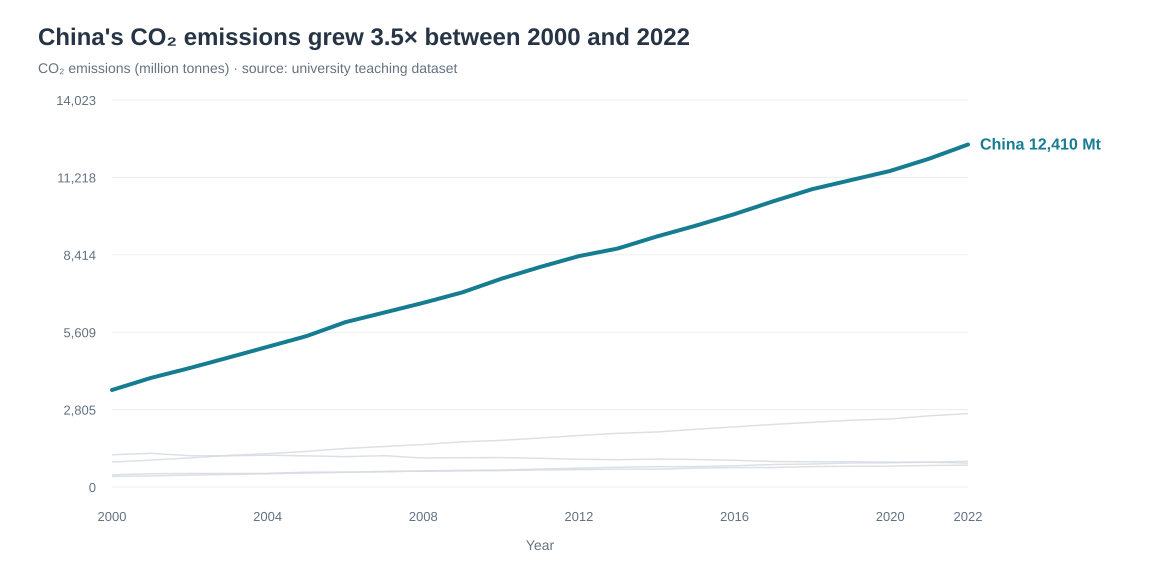

All 5 Asian countries included. China: 3,513.8 Mt → 12,409.5 Mt (3.53×).


In [4]:
# Task 2: All Asian countries for context; highlight China's total CO₂.
asia = df[df['Region'] == 'Asia'].copy()
asia_highlight = 'China'
china_asia = asia[asia['Country'] == asia_highlight].sort_values('Year')
start_mt = china_asia.loc[china_asia['Year'] == first_year, 'CO2_Mt'].iloc[0]
end_mt = china_asia.loc[china_asia['Year'] == last_year, 'CO2_Mt'].iloc[0]
growth_multiple = end_mt / start_mt
fig2 = go.Figure()
for country, country_data in asia[asia['Country'] != asia_highlight].groupby('Country'):
    fig2.add_trace(go.Scatter(
        x=country_data['Year'], y=country_data['CO2_Mt'],
        mode='lines', name=country, line=dict(color='#EEEEEE', width=1.5),
        hovertemplate=f'{country}<br>Year: %{{x}}<br>CO₂ emissions: %{{y:,.0f}} Mt<extra></extra>',
        showlegend=False
    ))

fig2.add_trace(go.Scatter(
    x=china_asia['Year'], y=china_asia['CO2_Mt'],
    mode='lines', name=asia_highlight, line=dict(color='#167C91', width=3.5),
    hovertemplate='China<br>Year: %{x}<br>CO₂ emissions: %{y:,.0f} Mt<extra></extra>',
    showlegend=False
))
fig2.add_annotation(
    x=last_year, y=end_mt, text=f'<b>{asia_highlight}</b>  {end_mt:,.0f} Mt',
    showarrow=False, xanchor='left', xshift=10,
    font=dict(color='#167C91', size=13)
)
fig2.update_layout(
    title=dict(text=f"China's CO₂ emissions grew {growth_multiple:.1f}× between {first_year} and {last_year}", x=0.02),
    xaxis=dict(title=None, range=[first_year, last_year + 4], dtick=4,
               showgrid=False, zeroline=False, showline=False),
    yaxis=dict(title='CO₂ emissions (million tonnes)', rangemode='tozero',
               showgrid=True, gridcolor='#F3F3F3', zeroline=False, showline=False, tickformat=',d'),
    template='plotly_white', height=460,
    margin=dict(l=95, r=175, t=88, b=50),
    font=dict(family='Arial', size=12, color='#283445'),
    paper_bgcolor='white', plot_bgcolor='white', showlegend=False
)
assert len(fig2.data) == asia['Country'].nunique()
assert sum(t.line.color != '#EEEEEE' for t in fig2.data) == 1
fig2.show()
print(f'All {asia["Country"].nunique()} Asian countries included. China: {start_mt:,.1f} Mt → {end_mt:,.1f} Mt ({growth_multiple:.2f}×).')


### Short explanation of the design

- **Context vs focus:** Every required country is visible in light grey (\`#EEEEEE\`), but only China is highlighted in colour.
- **Direct labels:** China is identified at the end of its line instead of in a legend.
- **Insight titles:** Titles communicate the change from 2000 to 2022.
- **Clean design:** No chart borders, heavy gridlines, or rotated text.

In the supplied classroom dataset, China's per-capita value rises from 1.32 to 4.37 (+231%), while its total emissions rise from 3,513.8 Mt to 12,409.5 Mt (3.53×). Treat these as figures from the course CSV rather than independently verified real-world statistics.
